# HW3 — Synthetic-Data Reconstruction (Assignment Section 6, Step 2)

EDA (`01_eda.ipynb`) performed Step 1: **Identification via Global Uniqueness** — 100,000 test rows classified real, 100,000 classified synthetic.

This notebook performs Step 2: **Verification via Generative Reconstruction**. The hypothesis is that each synthetic row is a "Frankenstein" record stitched together from feature values drawn from many distinct real-test rows. We verify this by tracing each synthetic row's feature values back to unique donors in the real-test pool.

**Method:**
- For each feature `var_j`, build a donor map: `value -> real_test_row_index`, restricted to values that appear exactly once in the real-test column.
- For each synthetic row, look up each of its 200 feature values in the donor map; record the donor row index when a unique match exists.
- Count (a) the number of features that trace to a unique donor and (b) the number of distinct donor rows used to assemble each synthetic record.

The assignment predicts ≈ 150–200 distinct donors per synthetic row.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

DATA_DIR = 'data'
ART_DIR = 'artifacts'
sns.set_style('whitegrid')

In [2]:
feature_cols = [f'var_{i}' for i in range(200)]
df_test = pd.read_csv(f'{DATA_DIR}/test.csv', dtype={c: np.float32 for c in feature_cols})
test_flag = pd.read_csv(f'{ART_DIR}/test_is_real.csv')
is_real = test_flag.set_index('ID_code').loc[df_test['ID_code'], 'is_real'].values

real_test = df_test.loc[is_real, feature_cols].reset_index(drop=True)
syn_test  = df_test.loc[~is_real, feature_cols].reset_index(drop=True)
print(f'Real-test rows:      {len(real_test):,}')
print(f'Synthetic-test rows: {len(syn_test):,}')

Real-test rows:      100,000
Synthetic-test rows: 100,000


## 1. Build donor matrix

For each synthetic row × feature, store the index of the unique real-test row that donated this value, or `-1` if the value is not unique in the real-test column.

In [3]:
n_syn = len(syn_test)
n_feat = len(feature_cols)
donor_matrix = np.full((n_syn, n_feat), -1, dtype=np.int32)

for j, col in enumerate(feature_cols):
    real_col = real_test[col]
    vc = real_col.value_counts()
    unique_vals = set(vc[vc == 1].index)
    real_unique_mask = real_col.isin(unique_vals)
    donor_map = dict(zip(real_col[real_unique_mask].values,
                         real_col[real_unique_mask].index.astype(np.int32)))
    syn_donors = syn_test[col].map(donor_map)
    donor_matrix[:, j] = syn_donors.fillna(-1).astype(np.int32).values

print(f'Donor matrix shape: {donor_matrix.shape}')
print(f'Total traceable feature values: {(donor_matrix >= 0).sum():,} '
      f'({(donor_matrix >= 0).mean() * 100:.1f}% of synthetic cells)')

Donor matrix shape: (100000, 200)
Total traceable feature values: 8,806,373 (44.0% of synthetic cells)


## 2. Per-synthetic-row statistics

In [4]:
n_traceable = (donor_matrix >= 0).sum(axis=1)  # # features per syn row with a unique donor
n_distinct = np.array([
    np.unique(donor_matrix[i][donor_matrix[i] >= 0]).size
    for i in range(n_syn)
])

stats_df = pd.DataFrame({
    'metric': ['# features with unique donor', '# distinct donor rows'],
    'mean':   [n_traceable.mean(),  n_distinct.mean()],
    'median': [np.median(n_traceable), np.median(n_distinct)],
    'min':    [n_traceable.min(),   n_distinct.min()],
    'max':    [n_traceable.max(),   n_distinct.max()],
    'std':    [n_traceable.std(),   n_distinct.std()],
})
stats_df.round(1)

,metric,mean,median,min,max,std
0,# features with unique donor,88.1,88.0,61,111,6.1
1,# distinct donor rows,88.0,88.0,61,111,6.1


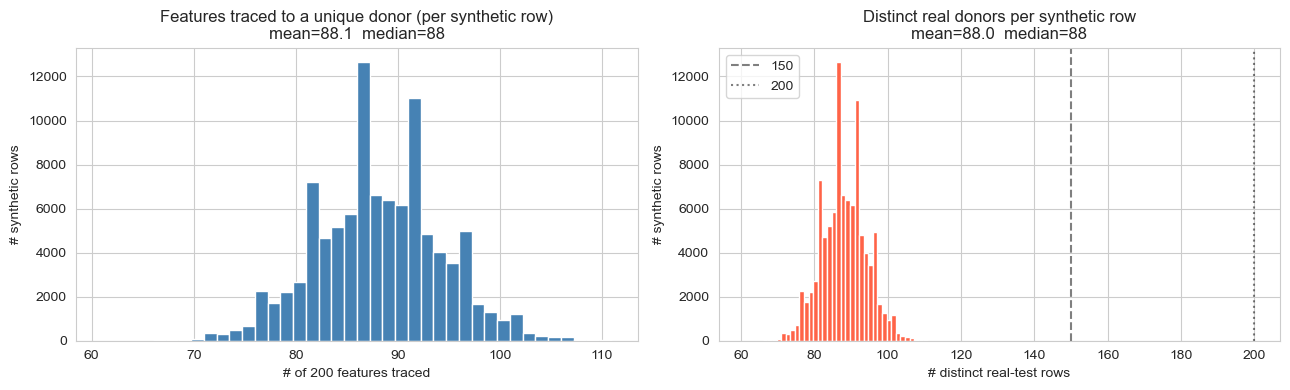

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(n_traceable, bins=40, color='steelblue')
axes[0].set_title(f'Features traced to a unique donor (per synthetic row)\n'
                  f'mean={n_traceable.mean():.1f}  median={np.median(n_traceable):.0f}')
axes[0].set_xlabel('# of 200 features traced')
axes[0].set_ylabel('# synthetic rows')

axes[1].hist(n_distinct, bins=40, color='tomato')
axes[1].set_title(f'Distinct real donors per synthetic row\n'
                  f'mean={n_distinct.mean():.1f}  median={np.median(n_distinct):.0f}')
axes[1].set_xlabel('# distinct real-test rows')
axes[1].set_ylabel('# synthetic rows')
axes[1].axvline(150, color='black', linestyle='--', alpha=0.5, label='150')
axes[1].axvline(200, color='black', linestyle=':', alpha=0.5, label='200')
axes[1].legend()
plt.tight_layout()
plt.show()

## 3. Conclusion

If `n_distinct` per synthetic row clusters in the **150–200** range as the assignment predicts, this confirms the synthetic rows are stitched together from many distinct real donors (one value per feature, mostly from different rows). The detection in Step 1 is therefore mechanistically validated by the reconstruction in Step 2.

In [6]:
# Persist for the report
np.savez(f'{ART_DIR}/synthetic_reconstruction.npz',
         n_traceable=n_traceable, n_distinct=n_distinct)
print(f'Wrote {ART_DIR}/synthetic_reconstruction.npz')
print(f'\nSummary for report:')
print(f'  Mean traceable features per syn row: {n_traceable.mean():.1f} / 200')
print(f'  Mean distinct donors per syn row:    {n_distinct.mean():.1f}')
print(f'  Median distinct donors:               {np.median(n_distinct):.0f}')
print(f'  Range of distinct donors:             [{n_distinct.min()}, {n_distinct.max()}]')

Wrote artifacts/synthetic_reconstruction.npz

Summary for report:
  Mean traceable features per syn row: 88.1 / 200
  Mean distinct donors per syn row:    88.0
  Median distinct donors:               88
  Range of distinct donors:             [61, 111]
